# Olive risk history, 2021–2025

> **Engine rules-0.5 · starting heuristics, to be validated by an agronomist · weather: Open-Meteo archive**

What would the AgroPulse risk engine have said on every day of the last 5 years?
We ran the real engine (`src/lib/risk`) on hourly weather for 4 olive regions, with **no field signals** (no scans, sprays or traps),
so these are the *weather-only* risks. (Since rules-0.5, peacock spot and anthracnose need wet weather, and anthracnose and olive fly also need ripe fruit; weather alone shows olive fly at Medium at most, because High needs a trap count or a sting scan.) The engine saw only a sliding window of weather (45 days before, the day, 6 days after), as it would in the app.

| Region | Country |
|---|---|
| Ayvalık, Edremit | Türkiye |
| Kalamata, Chania | Greece |

**How to read it:** a day counts as **High risk** when the engine score is 65 or more (0–100 scale), and **Medium** from 35. Olive fly is shown at **Medium** because weather alone cannot make it High.

In [1]:
import calendar
import os
import textwrap

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

# Figures are saved in research/figures/ (or ./figures/ when the notebook runs from research/).
cwd = os.path.basename(os.getcwd())
FIG_DIR = 'figures' if cwd == 'research' else ('research/figures' if os.path.isdir('research') else 'figures')
os.makedirs(FIG_DIR, exist_ok=True)

# Slide-ready figures: 16:9 (16 x 9 in at 200 dpi = 3200 x 1800 px, scales to 1920 x 1080), white background.
FIG_SIZE = (16, 9)
mpl.rcParams.update({
    'figure.figsize': FIG_SIZE, 'figure.dpi': 80, 'savefig.dpi': 200, 'savefig.facecolor': 'white',
    'font.size': 16, 'axes.titlesize': 18, 'axes.titleweight': 'bold', 'axes.labelsize': 15,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'axes.axisbelow': True,
    'grid.color': '#E6E6E2', 'grid.linewidth': 0.8, 'legend.frameon': False, 'legend.fontsize': 14,
})
TR_COLOR, GR_COLOR = '#C9553A', '#2E6FB0'
LOC_COLORS = {'Ayvalık': '#C9553A', 'Edremit': '#E0A526', 'Kalamata': '#2E6FB0', 'Chania': '#3F6B2F'}
MONTHS = [calendar.month_abbr[m] for m in range(1, 13)]
SUBTITLE = 'Rule-based estimates from real weather · engine rules-0.5 · data: Open-Meteo archive 2021–2025'


def headline(fig, title, subtitle=SUBTITLE, top=0.86):
    # Title and the small grey subtitle at the top of a slide figure, and room for them.
    fig.subplots_adjust(top=top)
    fig.text(0.5, 0.965, title, ha='center', va='top', fontsize=26, fontweight='bold')
    fig.text(0.5, 0.905, subtitle, ha='center', va='top', fontsize=14, color='#6B6B6B')


def save(fig, name):
    fig.savefig(f'{FIG_DIR}/{name}')  # fixed 16:9 size: no tight bounding box, so the ratio stays exact
    plt.show()

In [2]:
# Load backtest.csv. It is in research/data/. On Google Colab, upload it when asked.
CANDIDATES = ['backtest.csv', 'data/backtest.csv', 'research/data/backtest.csv']
path = next((p for p in CANDIDATES if os.path.exists(p)), None)
if path is None:
    try:
        from google.colab import files  # only exists on Colab
        print('Upload research/data/backtest.csv')
        path = next(iter(files.upload()))
    except ImportError:
        raise FileNotFoundError('backtest.csv not found. Run: npx tsx research/scripts/backtest.ts')

df = pd.read_csv(path, parse_dates=['date'])
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['high'] = df['level'].eq('High')
print(f'{len(df):,} rows · {df.location.nunique()} locations · {df.date.min():%Y-%m-%d} to {df.date.max():%Y-%m-%d}')
df.head()

73,040 rows · 4 locations · 2021-01-01 to 2025-12-31


,location,country,date,threat,score,level,top_driver,year,month,high
0,Ayvalık,TR,2021-01-01,peacock-spot,17,Low,NaN,2021,1,False
1,Ayvalık,TR,2021-01-01,olive-fly,16,Low,Olives are on the tree (harvest),2021,1,False
2,Ayvalık,TR,2021-01-01,olive-moth,39,Medium,Moth activity is low in the harvest stage,2021,1,False
3,Ayvalık,TR,2021-01-01,anthracnose,36,Medium,Fruit is ripe or nearly ripe (harvest),2021,1,False
4,Ayvalık,TR,2021-01-01,olive-knot,90,High,Hail-like wind or frost in the last days can w...,2021,1,True


## 1. When are the main pests and diseases at risk?

Average number of risk days per month (High, and Medium for olive fly), Türkiye (Ayvalık, Edremit) against Greece (Kalamata, Chania).

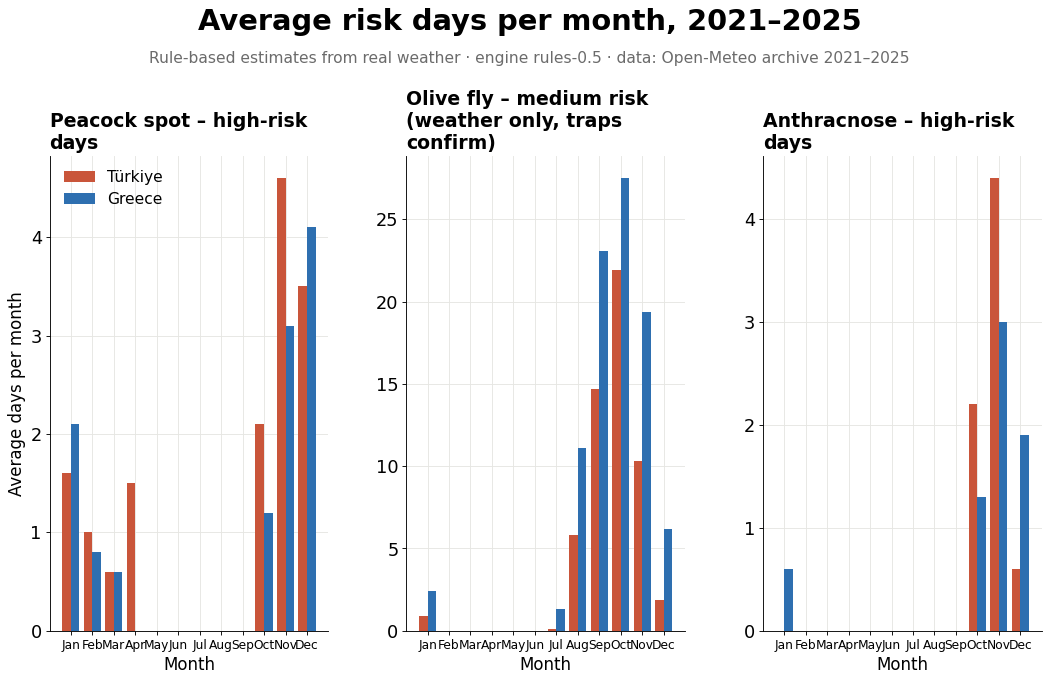

In [3]:
# Olive fly: weather alone never reaches High, so its panel counts Medium days.
THREATS = [
    ('peacock-spot', 'Peacock spot – high-risk days', 'High'),
    ('olive-fly', 'Olive fly – medium risk (weather only, traps confirm)', 'Medium'),
    ('anthracnose', 'Anthracnose – high-risk days', 'High'),
]

# Days per location, year and month at the chosen level; then the average per country and month.
days = (pd.concat([df[(df.threat == t) & (df.level == lv)] for t, _, lv in THREATS])
        .groupby(['country', 'location', 'year', 'month', 'threat']).size().rename('days').reset_index())
full = pd.MultiIndex.from_product(
    [df.country.unique(), df.location.unique(), sorted(df.year.unique()), range(1, 13), [t for t, _, _ in THREATS]],
    names=['country', 'location', 'year', 'month', 'threat'])
# Keep only real country-location pairs.
pairs = df[['country', 'location']].drop_duplicates()
full = full.to_frame(index=False).merge(pairs, on=['country', 'location'])
days = full.merge(days, how='left', on=list(full.columns)).fillna({'days': 0})
avg = days.groupby(['country', 'threat', 'month']).days.mean().unstack('country')

fig, axes = plt.subplots(1, 3, figsize=FIG_SIZE)
x = np.arange(12)
for ax, (key, name, _) in zip(axes, THREATS):
    a = avg.xs(key, level='threat')
    ax.bar(x - 0.2, a['TR'].reindex(range(1, 13)).values, 0.4, color=TR_COLOR, label='Türkiye')
    ax.bar(x + 0.2, a['GR'].reindex(range(1, 13)).values, 0.4, color=GR_COLOR, label='Greece')
    ax.set_title(textwrap.fill(name, 26), fontsize=17, loc='left')
    ax.set_xticks(x)
    ax.set_xticklabels(MONTHS, fontsize=11)
    ax.set_xlabel('Month')
axes[0].set_ylabel('Average days per month')
axes[0].legend(loc='upper left')
headline(fig, 'Average risk days per month, 2021–2025', top=0.76)
fig.subplots_adjust(bottom=0.1, wspace=0.28)
save(fig, '1_high_days_per_month.png')

## 2. Peacock spot in Ayvalık, year by year

High-risk days of peacock spot for each month. The disease follows the wet months, and some years are much worse than others.

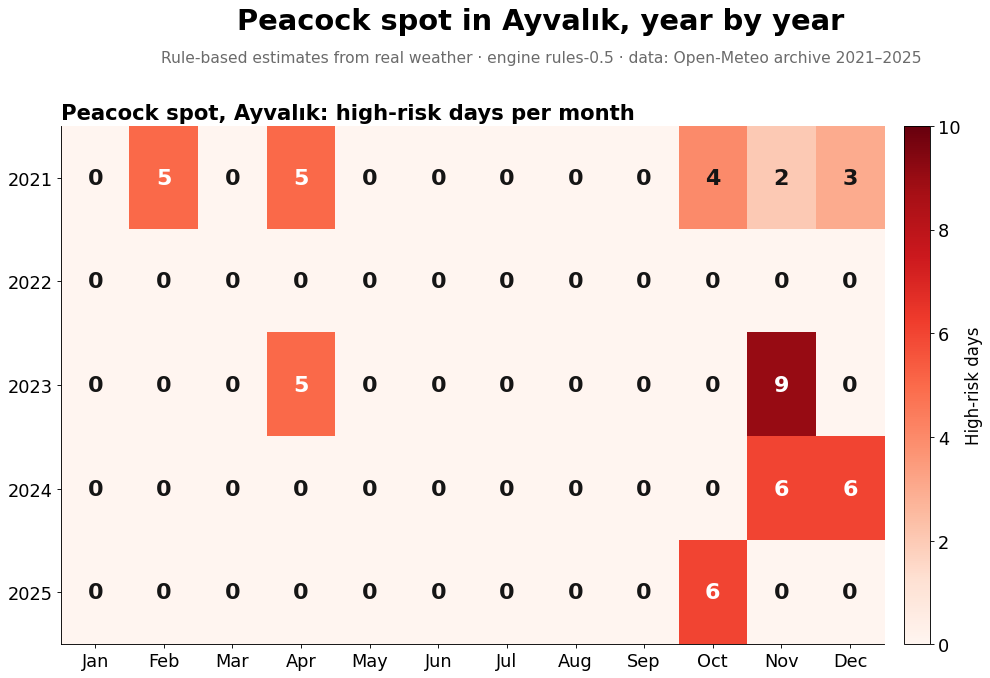

In [4]:
pv = (df[(df.location == 'Ayvalık') & (df.threat == 'peacock-spot') & df.high]
      .groupby(['year', 'month']).size().unstack(fill_value=0)
      .reindex(index=sorted(df.year.unique()), columns=range(1, 13), fill_value=0))

fig, ax = plt.subplots(figsize=FIG_SIZE)
im = ax.imshow(pv.values, cmap='Reds', aspect='auto', vmin=0, vmax=max(10, pv.values.max()))
ax.set_xticks(range(12))
ax.set_xticklabels(MONTHS)
ax.set_yticks(range(len(pv.index)))
ax.set_yticklabels(pv.index)
ax.grid(False)
for i in range(pv.shape[0]):
    for j in range(12):
        v = pv.values[i, j]
        ax.text(j, i, int(v), ha='center', va='center', fontsize=20, fontweight='bold',
                color='white' if v > pv.values.max() * 0.55 else '#151515')
cb = fig.colorbar(im, ax=ax, pad=0.02)
cb.set_label('High-risk days')
ax.set_title('Peacock spot, Ayvalık: high-risk days per month', fontsize=19, loc='left')
headline(fig, 'Peacock spot in Ayvalık, year by year', top=0.80)
fig.subplots_adjust(bottom=0.08)
save(fig, '2_peacock_spot_ayvalik_heatmap.png')

## Appendix: weather hazards per year

High-risk days per year for frost, heat stress, strong wind and drought.

> **Drought is more meaningful here than in the app.** The app only sees about 3 weeks of past weather, so it cannot count dry spells of 30 days.
> This backtest sees the whole history, so drought can reach its full score.

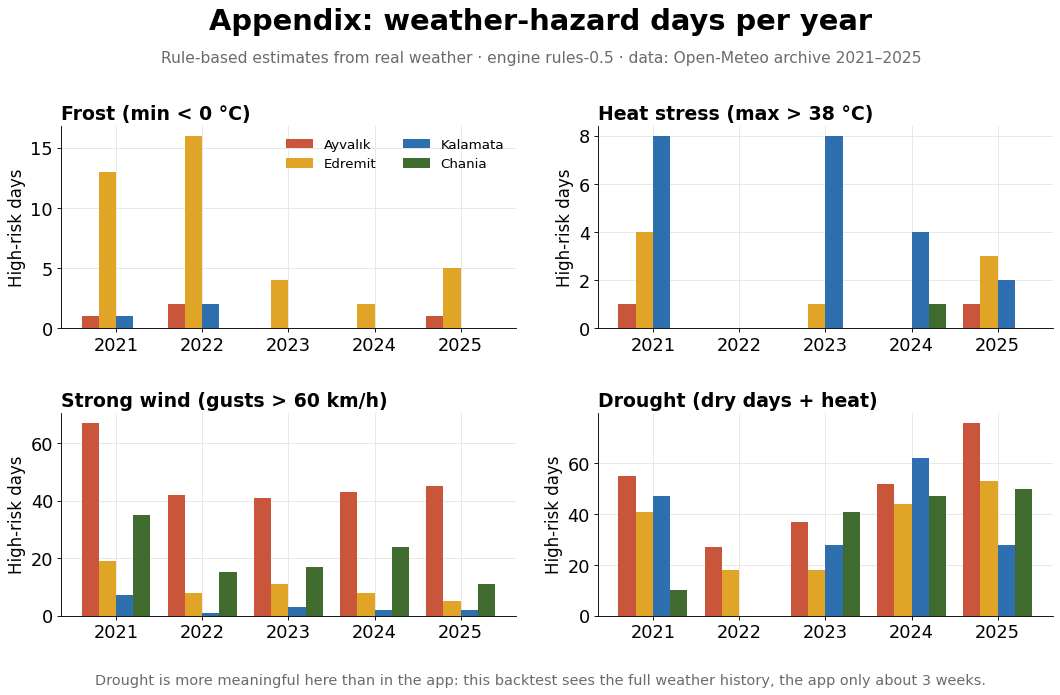

In [5]:
HAZARDS = [('frost', 'Frost (min < 0 °C)'), ('heat', 'Heat stress (max > 38 °C)'),
           ('wind', 'Strong wind (gusts > 60 km/h)'), ('drought', 'Drought (dry days + heat)')]
years = sorted(df.year.unique())
order = ['Ayvalık', 'Edremit', 'Kalamata', 'Chania']

h = (df[df.high & df.threat.isin([k for k, _ in HAZARDS])]
     .groupby(['threat', 'location', 'year']).size().rename('days').reset_index())

fig, axes = plt.subplots(2, 2, figsize=FIG_SIZE)
for ax, (key, name) in zip(axes.ravel(), HAZARDS):
    sub = h[h.threat == key].pivot(index='year', columns='location', values='days').reindex(index=years, columns=order).fillna(0)
    xs = np.arange(len(years))
    for k, loc in enumerate(order):
        ax.bar(xs + (k - 1.5) * 0.2, sub[loc].values, 0.2, color=LOC_COLORS[loc], label=loc)
    ax.set_xticks(xs)
    ax.set_xticklabels(years)
    ax.set_title(name, fontsize=17, loc='left')
    ax.set_ylabel('High-risk days')
axes[0, 0].legend(ncol=2, loc='upper right', fontsize=12)
headline(fig, 'Appendix: weather-hazard days per year', top=0.80)
fig.subplots_adjust(bottom=0.12, hspace=0.42, wspace=0.18)
fig.text(0.5, 0.025, 'Drought is more meaningful here than in the app: this backtest sees the full weather history, the app only about 3 weeks.',
         ha='center', fontsize=13, color='#6B6B6B')
save(fig, 'appendix_weather_hazards.png')

## Summary: high-risk days per year (average of 2021–2025)

High-risk days for every threat, plus Medium days for olive fly and peacock spot (two of the models that were restructured in rules-0.4 and rules-0.5).

threat,Country,Peacock spot,Olive moth,Anthracnose,Olive knot,Frost,Heat stress,Strong wind,Drought,Olive fly (Medium),Peacock spot (Medium)
location,,,,,,,,,,,
Ayvalık,Türkiye,10.2,41.4,7.4,34.8,0.8,0.4,47.6,49.4,60.0,73.6
Edremit,Türkiye,19.6,42.4,7.0,20.0,8.0,1.6,10.2,34.8,51.2,55.8
Kalamata,Greece,23.8,46.4,13.6,6.6,0.6,4.4,3.0,33.0,71.8,76.8
Chania,Greece,0.0,56.6,0.0,8.6,0.0,0.2,20.4,29.6,110.2,71.4


*Olive fly High requires trap counts.*

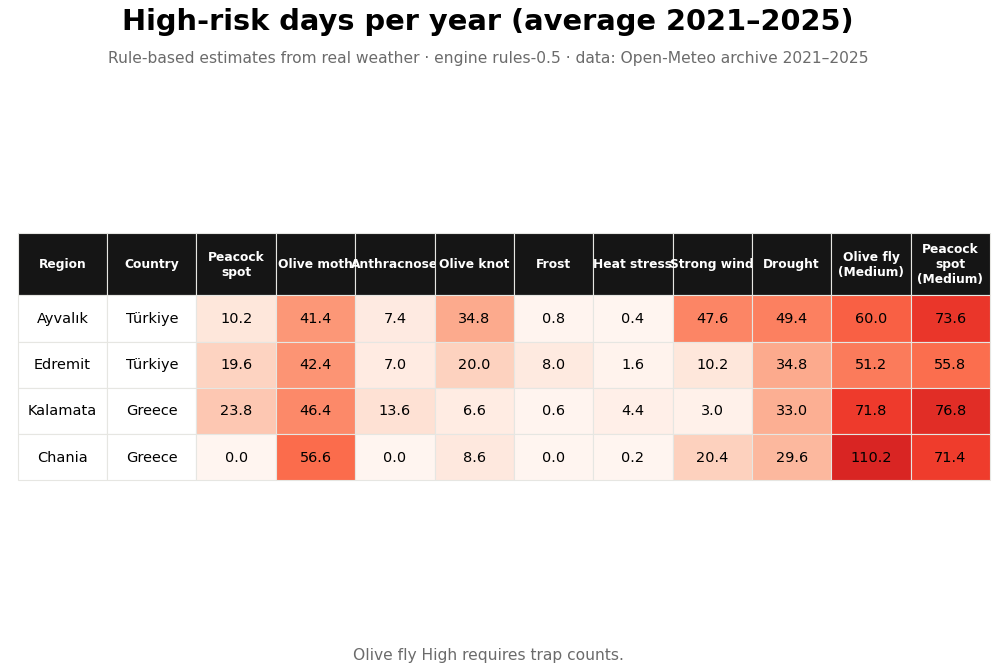

In [6]:
NAMES = {'peacock-spot': 'Peacock spot', 'olive-moth': 'Olive moth', 'anthracnose': 'Anthracnose',
         'olive-knot': 'Olive knot', 'frost': 'Frost', 'heat': 'Heat stress', 'wind': 'Strong wind', 'drought': 'Drought'}
n_years = df.year.nunique()
summary = (df[df.high & df.threat.isin(NAMES)].groupby(['location', 'threat']).size().unstack(fill_value=0) / n_years)
summary = summary.reindex(index=order, columns=list(NAMES)).fillna(0).round(1).rename(columns=NAMES)
# Olive fly is shown at Medium only: weather alone cannot make it High.
medium = (df[(df.level == 'Medium') & df.threat.isin(['olive-fly', 'peacock-spot'])].groupby(['location', 'threat']).size().unstack(fill_value=0) / n_years).reindex(order).round(1)
summary['Olive fly (Medium)'] = medium['olive-fly']
summary['Peacock spot (Medium)'] = medium['peacock-spot']
summary.insert(0, 'Country', ['Türkiye', 'Türkiye', 'Greece', 'Greece'])
FOOTNOTE = 'Olive fly High requires trap counts.'
summary.to_csv(f'{FIG_DIR}/summary_high_days_per_year.csv')
display(summary.style.background_gradient(cmap='Reds', subset=summary.columns[1:], axis=None).format({c: '{:.1f}' for c in summary.columns[1:]}))
display(Markdown(f'*{FOOTNOTE}*'))

# The same table as a slide figure.
cols = ['Country'] + [c for c in summary.columns if c != 'Country']
cells = [[loc] + [summary.loc[loc, c] if c == 'Country' else f'{summary.loc[loc, c]:.1f}' for c in cols] for loc in summary.index]
fig, ax = plt.subplots(figsize=FIG_SIZE)
ax.axis('off')
labels = [chr(10).join(textwrap.wrap(c, 11)) for c in ['Region'] + cols]
tbl = ax.table(cellText=cells, colLabels=labels, colWidths=[0.09, 0.09] + [0.08] * 10, loc='center', cellLoc='center')
tbl.auto_set_font_size(False)
tbl.set_fontsize(13)
tbl.scale(1, 3.6)
for (r, c), cell in tbl.get_celld().items():
    cell.set_edgecolor('#E6E6E2')
    if r == 0:
        cell.set_facecolor('#151515')
        cell.set_text_props(color='white', fontweight='bold', fontsize=11)
        cell.set_height(cell.get_height() * 1.35)
    elif c >= 2:
        v = float(cells[r - 1][c])
        cell.set_facecolor(plt.cm.Reds(min(v / 80, 1) * 0.7))
headline(fig, 'High-risk days per year (average 2021–2025)', top=0.85)
fig.text(0.5, 0.06, FOOTNOTE, ha='center', fontsize=14, color='#6B6B6B')
save(fig, '3_summary_table.png')

## Key findings

1. **Peacock spot is a wet-spell disease.** It is High on about **10 days a year in Ayvalık, 20 in Edremit and 24 in Kalamata**, and almost never in dry Chania.
   All of it falls between **October and April**, with a peak in **November–December** (about 3–5 High days a month) and none in summer.
2. **Fruit rot and olive fly need wet or mild weather AND ripe fruit.** Anthracnose is High on only **7 days a year in Ayvalık and Edremit and 14 in Kalamata** (none in Chania), almost all in
   **October–December** during wet spells, with Medium on 21–39 days. It varies a lot between years: Ayvalık had 15 High days in 2023 and none in 2022.
   Olive fly cannot reach High from weather alone; it is Medium on 51–72 days a year (110 in mild Chania), mainly **August–November**, and only a trap count or a sting scan can lift it to High.
3. **The other threats are local.** Olive knot is High on 2–10 % of days, mostly in **November–February** after frosts or storms with heavy rain.
   Frost matters in **Edremit** (about 8 days a year), heat in **Kalamata** (about 4), strong wind in **Ayvalık** (about 48 against 3 in Kalamata),
   and drought on 30–50 days a year everywhere, almost all in **June–September**.

*These are weather-only results from starting heuristics. They show how the engine behaves, not how often fields really got sick.
The next step is to compare them with real field reports and scans.*